<a href="https://colab.research.google.com/github/Antonioufrrj/scripts-graduacao/blob/master/text_friends.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import re
import requests
import zipfile
import sqlite3
import os
import json
import glob
import matplotlib.pyplot as plt
import numpy as np


In [ ]:
ID: 1434539083738, Campos: ['afraid', '<img src="afraid.jpg" />', '[sound:afraid.mp3]', '[sound:afraid_meaning.mp3]', '[sound:afraid_example.mp3]', 'When someone is afraid, they feel fear.', 'The woman was afraid of what she saw.']
comparar palavra com a lista

# extract text from "https://fangj.github.io/friends/"

In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import re
import nltk
from nltk.tokenize import word_tokenize
nltk.download("punkt_tab")
from nltk.corpus import stopwords
nltk.download("stopwords")

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:

# URL base
base_url = "https://fangj.github.io/friends/"

# Buscar lista de páginas de episódios
response = requests.get(base_url)
soup = BeautifulSoup(response.text, "html.parser")

pages = [base_url + a["href"] for a in soup.find_all("a", href=True)]

# Função para parsear cada episódio
def parse_episode(url):
    resp = requests.get(url)
    soup = BeautifulSoup(resp.text, "html.parser")

    # Pega todos os <p>
    ps = [p.get_text(strip=True) for p in soup.find_all("p")]

    # remove o primeiro <p> (título do episódio)
    ps = ps[1:]

    records = []
    for line in ps:
        # Extrair personagem (tudo antes de ":")
        character_match = re.match(r"^(\w+):", line)
        character = character_match.group(1) if character_match else None

        # Extrair fala (remover "Personagem: " do início)
        dialogue = re.sub(r"^\w+:\s*", "", line)
        dialogue = dialogue.replace('\n', ' ')

        # Extrair número do episódio (do link)
        episode_match = re.search(r"\d{4}", url)
        episode = episode_match.group(0) if episode_match else None

        if dialogue.strip():
            records.append({
                "url": url,
                "episode": episode,
                "character": character,
                "line": dialogue
            })

    return records

# Aplicar função em todas as páginas
friends_raw = []
for page in pages:
    friends_raw.extend(parse_episode(page))

# Converter para DataFrame
df = pd.DataFrame(friends_raw)

# Salvar em CSV
#df.to_csv("friends.csv", index=False)

print("Total de linhas extraídas:", len(df))
print(df.head())


Total de linhas extraídas: 62958
                                                url episode character  \
0  https://fangj.github.io/friends/season/0101.html    0101    Monica   
1  https://fangj.github.io/friends/season/0101.html    0101      Joey   
2  https://fangj.github.io/friends/season/0101.html    0101  Chandler   
3  https://fangj.github.io/friends/season/0101.html    0101    Phoebe   
4  https://fangj.github.io/friends/season/0101.html    0101      None   

                                                line  
0  There's nothing to tell! He's just some guy I ...  
1  C'mon, you're going out with the guy! There's ...  
2  All right Joey, be nice.So does he have a hump...  
3                           Wait, does he eat chalk?  
4                         (They all stare, bemused.)  


In [ ]:
friends = df.copy()

# Substituições
friends["line"] = friends["line"].str.replace(r"[\u0091\u0092]", "'", regex=True)
friends["line"] = friends["line"].str.replace(r"\u0097", "-", regex=True)

# Remover texto entre parênteses e colchetes (inclusive multilinha)
friends["line"] = friends["line"].str.replace(r"\([^)]*\)", "", regex=True)
friends["line"] = friends["line"].str.replace(r"\[[^]]*\]", "", regex=True)

# Remover espaços extras
friends["line"] = friends["line"].str.strip()

# Filtrar linhas não vazias
friends = friends[friends["line"] != ""]

# Mostrar as 10 primeiras (equivalente ao head + select)
print(friends.loc[:, ["episode", "character", "line"]].head(10))

   episode character                                               line
0     0101    Monica  There's nothing to tell! He's just some guy I ...
1     0101      Joey  C'mon, you're going out with the guy! There's ...
2     0101  Chandler  All right Joey, be nice.So does he have a hump...
3     0101    Phoebe                           Wait, does he eat chalk?
5     0101    Phoebe  Just, 'cause, I don't want her to go through w...
6     0101    Monica  Okay, everybody relax. This is not even a date...
7     0101  Chandler                          Sounds like a date to me.
9     0101  Chandler  Alright, so I'm back in high school, I'm stand...
10    0101       All                          Oh, yeah. Had that dream.
11    0101  Chandler  Then I look down, and I realize there's a phon...


In [ ]:
# Tokenizar as falas em palavras
friends["tokens"] = friends["line"].apply(lambda x: word_tokenize(x.lower()))
# Explodir a lista de tokens em linhas
words = friends.explode("tokens").rename(columns={"tokens": "word"})
# Remover palavras vazias ou não alfabéticas
words = words[words["word"].str.isalpha()]

stop_words = set(stopwords.words("english"))
# Manter apenas palavras alfabéticas e que não sejam stopwords
words = words[words["word"].str.isalpha()]
words = words[~words["word"].isin(stop_words)]


In [ ]:
import spacy

# carregar modelo em inglês
nlp = spacy.load("en_core_web_sm")

# função para lematizar
def lemmatize_word(word):
    doc = nlp(word)
    return doc[0].lemma_

# aplicar a lematização
words["word"] = words["word"].apply(lemmatize_word)

In [ ]:
words.head(1)

,url,episode,character,line,word
0,https://fangj.github.io/friends/season/0101.html,0101,Monica,There's nothing to tell! He's just some guy I ...,nothing


In [ ]:
# Contagem de palavras
word_counts = (
    words["word"]
    .value_counts()
    .reset_index()
    .rename(columns={"index": "word"})
)
# pega a primeira ocorrência (episódio + linha) de cada palavra
first_occurrence = (
    words
    .drop_duplicates(subset=["word"], keep="first")  # mantém só a primeira vez que cada palavra apareceu
    .loc[:, ["word", "episode", "line"]]             # mantém colunas desejadas
)

# junta com a contagem
word_counts = word_counts.merge(first_occurrence, on="word", how="left")

word_counts.head(10)

,word,count,episode,line
0,oh,8334,0101,"Just, 'cause, I don't want her to go through w..."
1,know,6569,0101,"All of a sudden, the phone starts to ring.Now ..."
2,get,5827,0101,"C'mon, you're going out with the guy! There's ..."
3,well,5167,0101,"Finally, I figure I'd better answer it,and it ..."
4,yeah,5109,0101,"Oh, yeah. Had that dream."
5,okay,4690,0101,"Okay, everybody relax. This is not even a date..."
6,go,4658,0101,"C'mon, you're going out with the guy! There's ..."
7,hey,4064,0101,"And hey, you need anything, you can always com..."
8,na,3795,0101,"This guy says hello, I wanna kill myself."
9,think,3642,0101,"Just breathe, breathe.. that's it. Just try to..."


In [ ]:
#word_counts.to_csv("friends_words_counts.csv", index=False)

In [ ]:
len(word_counts[word_counts['episode'] == '0101'])

591

In [ ]:
word_counts["cumsum"] = word_counts["count"].cumsum()
word_counts["cumprop"] = word_counts["cumsum"] / word_counts["count"].sum()
word_counts["index"] = range(1, len(word_counts) + 1)

# Mostrar top 10
print(word_counts.head(10))

    word  count episode                                               line  \
0     oh   8334    0101  Just, 'cause, I don't want her to go through w...   
1   know   6569    0101  All of a sudden, the phone starts to ring.Now ...   
2    get   5827    0101  C'mon, you're going out with the guy! There's ...   
3   well   5167    0101  Finally, I figure I'd better answer it,and it ...   
4   yeah   5109    0101                          Oh, yeah. Had that dream.   
5   okay   4690    0101  Okay, everybody relax. This is not even a date...   
6     go   4658    0101  C'mon, you're going out with the guy! There's ...   
7    hey   4064    0101  And hey, you need anything, you can always com...   
8     na   3795    0101          This guy says hello, I wanna kill myself.   
9  think   3642    0101  Just breathe, breathe.. that's it. Just try to...   

   cumsum   cumprop  index  
0    8334  0.026290      1  
1   14903  0.047013      2  
2   20730  0.065395      3  
3   25897  0.081695      

In [ ]:
def palavras_para_prop(dff, prop):
    return dff.loc[dff["cumprop"] >= prop, "index"].iloc[0]

# Proporções que você quer calcular
props = [0.98, 0.95, 0.9, 0.5]

palavras_para_prop_resultado = pd.DataFrame({
    "prop": props,
    "palavras": [palavras_para_prop(word_counts, p) for p in props]
})

print(palavras_para_prop_resultado)


   prop  palavras
0  0.98      6539
1  0.95      3342
2  0.90      1593
3  0.50        88


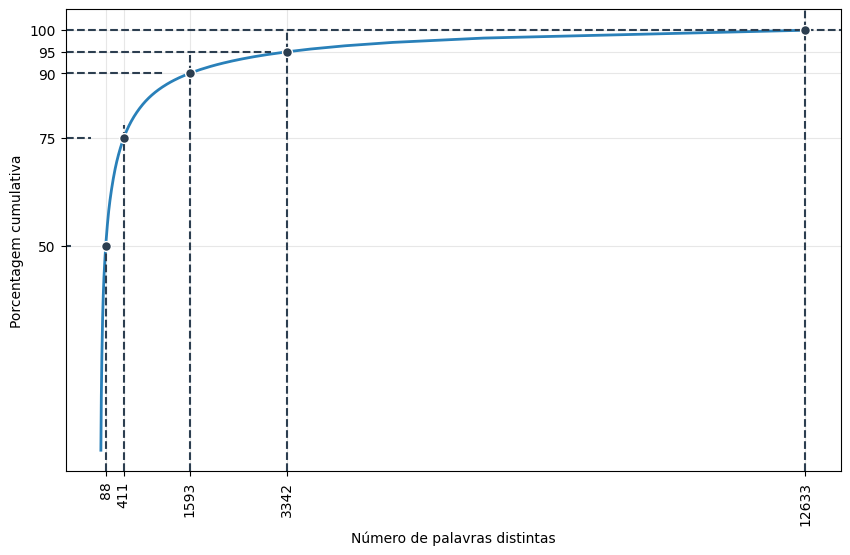

In [ ]:
# proporções de interesse
props = np.array([0.50, 0.75, 0.90, 0.95, 1.0])

# encontra o menor índice onde a cumprop >= proporção desejada
x_ticks = [word_counts.loc[word_counts["cumprop"] >= p, "index"].iloc[0] for p in props]

plt.figure(figsize=(10,6))

# curva cumulativa
plt.plot(word_counts["index"], word_counts["cumprop"]*100,
         color="#2980b9", linewidth=2)

# adicionar linhas de referência
for p, x in zip(props, x_ticks):
    plt.axhline(y=p*100, xmax=x/word_counts["index"].max(),
                linestyle="--", color="#2c3e50")
    plt.axvline(x=x, ymax=p,
                linestyle="--", color="#2c3e50")
    plt.scatter(x, p*100,
                color="#2c3e50", s=50, zorder=5, edgecolor="white")

# rótulos nos eixos
plt.xlabel("Número de palavras distintas")
plt.ylabel("Porcentagem cumulativa")
plt.title("")

# ticks em Y (como você já definiu)
plt.yticks([50, 75, 90, 95, 100])

# ticks em X correspondendo a esses pontos
plt.xticks(x_ticks, [f"{x}" for x in x_ticks])

# plotar eixo x no angulo de 90 graus
plt.xticks(rotation=90)

plt.grid(alpha=0.3)
plt.show()

#  anki 4000 words

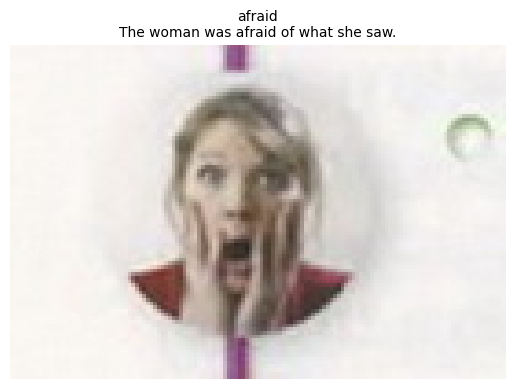

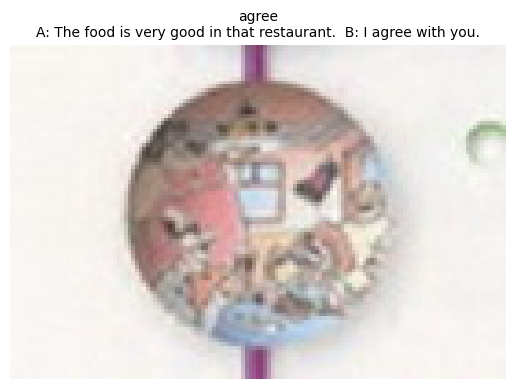

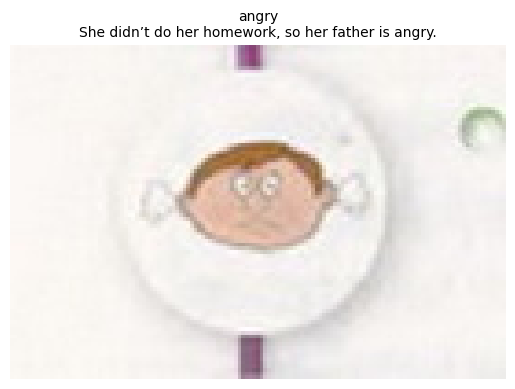

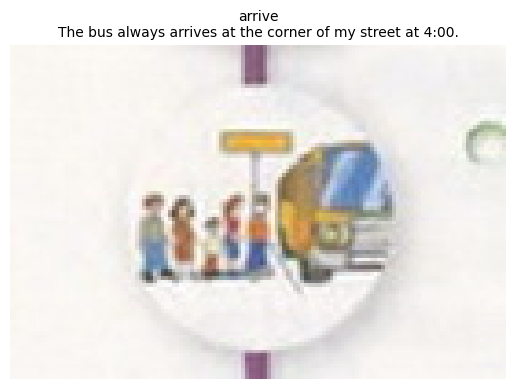

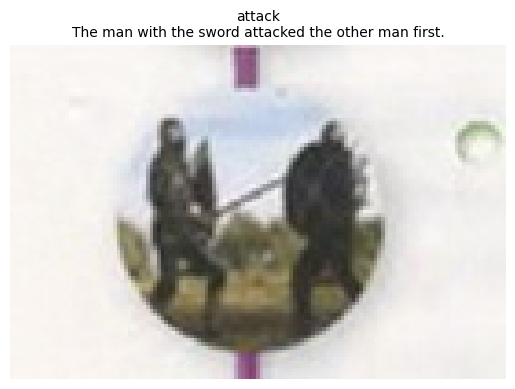

In [ ]:
import os
import re
import sqlite3
import zipfile
import json
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Caminho do arquivo .apkg
apkg_path = "/content/4000_Essential_English_Words_all_books_en-en_M4R4M.apkg"

# Pasta temporária para extrair
extract_path = "deck_temp"
os.makedirs(extract_path, exist_ok=True)

# 1. Extrair o .apkg
with zipfile.ZipFile(apkg_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# 2. Abrir o banco de dados collection.anki2
db_path = os.path.join(extract_path, "collection.anki2")
conn = sqlite3.connect(db_path)
cursor = conn.cursor()

# 3. Ler as notas
cursor.execute("SELECT id, flds FROM notes")
notes = cursor.fetchall()




In [ ]:
# 4. Carregar mapeamento do arquivo 'media'
media_map_path = os.path.join(extract_path, "media")
with open(media_map_path, "r", encoding="utf-8") as f:
    media_map = json.load(f)  # { "0": "immigrant.jpg", "1": "immigrant.mp3", ... }

# 5. Inverter o dicionário: nome real -> id numérico
media_lookup = {v: k for k, v in media_map.items()}

# 6. Loop pelas notas e exibir imagens
for note_id, fields in notes[:5]:  # só as 5 primeiras para teste
    campos = fields.split("\x1f")

    if len(campos) < 2:
        continue

    word = campos[0]  # primeira coluna é a palavra
    img_html = campos[1]  # segunda coluna pode ter a imagem
    example_sentence = campos[-1]  # último campo é frase de exemplo

    # procurar por <img src="...">
    match = re.search(r'src="([^"]+)"', img_html)
    if match:
        img_name = match.group(1)  # ex: immigrant.jpg
        if img_name in media_lookup:
            img_id = media_lookup[img_name]  # ex: "23"
            img_path = os.path.join(extract_path, img_id)  # ex: deck_temp/23

            if os.path.exists(img_path):
                img = mpimg.imread(img_path)
                plt.imshow(img)
                plt.axis("off")
                plt.title(f"{word}\n{example_sentence}", fontsize=10)
                plt.show()
            else:
                print(f"⚠️ Arquivo {img_id} não encontrado no deck")
        else:
            print(f"⚠️ {img_name} não está no media mapping")

[(1434539083738,
  'afraid\x1f<img src="afraid.jpg" />\x1f[sound:afraid.mp3]\x1f[sound:afraid_meaning.mp3]\x1f[sound:afraid_example.mp3]\x1fWhen someone is afraid, they feel fear.\x1fThe woman was afraid of what she saw.'),
 (1434539083739,
  'agree\x1f<img src="agree.jpg" />\x1f[sound:agree.mp3]\x1f[sound:agree_meaning.mp3]\x1f[sound:agree_example.mp3]\x1fTo agree is to say “yes” or to think the same way.\x1fA: The food is very good in that restaurant.  B: I agree with you.'),
 (1434539083740,
  'angry\x1f<img src="angry.jpg" />\x1f[sound:angry.mp3]\x1f[sound:angry_meaning.mp3]\x1f[sound:angry_example.mp3]\x1fWhen someone is angry, they may want to speak loudly or fight.\x1fShe didn’t do her homework, so her father is angry.'),
 (1434539083741,
  'arrive\x1f<img src="arrive.jpg" />\x1f[sound:arrive.mp3]\x1f[sound:arrive_meaning.mp3]\x1f[sound:arrive_example.mp3]\x1fTo arrive is to get to or reach some place.\x1fThe bus always arrives at the corner of my street at 4:00.'),
 (1434539083

In [ ]:
c = []
for note_id, fields in notes:
    # Os campos são separados por caractere especial (normalmente 0x1f)
    campos = fields.split("\x1f")
    #print(f"ID: {note_id}, Campos: {campos}")
    c.append(campos)

In [ ]:
anki = []
nanki = []
ep1 = word_counts[word_counts['episode'] == '0101']
for i, row in ep1.iterrows():
  for item in c:
    if row['word'] == item[0]:
      #print(f"{row['word']} -> Palavra encontrada.")
      anki.append(item)
      break
  else:
    nanki.append(row)
    #print(f"{row['word']} -> Pp.")


In [ ]:
i

['wardrobe',
 '<img src="wardrobe.jpg" />',
 '[sound:wardrobe.mp3]',
 '[sound:wardrobe_meaning.mp3]',
 '[sound:wardrobe_example.mp3]',
 'A wardrobe is the collection of all of a person’s clothing.',
 'She bought some new clothes to expand her wardrobe.']